# A Bond Portfolio in QuantLib: DV01, PV01, CS01, Key-Rate Risk and Mark-to-Market, with an ML Surrogate for Scenario Revaluation

DV01, CS01 and key-rate risk are the daily language of a bond desk and of treasury risk teams. Computing them exactly means repricing every bond for every bump, and a VaR run needs thousands of scenarios on top of that. This notebook does the exact work on a real $1 billion portfolio and then trains machine-learning surrogates that give nearly the same answer much faster.

**What it does.** It prices a real $1 billion portfolio bond by bond in **QuantLib**: about 3,000 bonds from the holdings of the largest investment-grade corporate bond ETF and the broad Treasury ETF. Each bond is valued on a Treasury zero curve built from today's par yields, with its own z-spread calibrated to its market price.

**Risk measures** for every bond and for the portfolio:

- **DV01** (curve), **PV01** (one basis point of running coupon) and **CS01** (credit spread);
- **key-rate DV01s** and convexity.

**Scenario revaluation.** Thousands of historical 10-day scenarios of the Treasury curve and the IG credit spread are applied. Full QuantLib revaluation is the benchmark, against a second-order Taylor expansion and **machine-learning surrogates** (LightGBM and a Keras neural network) trained on a few hundred full revaluations.

The surrogate gives the portfolio's 99% VaR and expected shortfall at a fraction of the cost.

**Data.** iShares LQD and GOVT holdings, and FRED (Treasury constant-maturity yields, ICE BofA US Corporate index OAS).

**Methods.** QuantLib bond pricing, curve bootstrapping and z-spread calibration, bump-and-reprice sensitivities, historical scenario generation, LightGBM and Keras 3 surrogates, and VaR/ES.

## 1. The sensitivities a bond desk reports

| measure | definition | use |
|---|---|---|
| **MTM** | clean price × face, valued off the discount curve plus the bond's z-spread | P&L, collateral, limits |
| **DV01** | change in dirty value for a 1 bp parallel **fall** in the risk-free curve (spread unchanged) | rate hedging with futures or swaps |
| **PV01** | value of a 1 bp **annuity** on the bond's cash-flow dates: Σ τᵢ·DFᵢ × face × 0.0001 | converting spread or coupon changes into money; near DV01 for par bonds, but differs for premium/discount bonds |
| **CS01** | change in value for a 1 bp **widening** of the bond's z-spread (curve unchanged) | credit hedging with CDS or spread products |
| **key-rate DV01** | DV01 to a 1 bp bump of one point of the curve (2, 5, 10, 30Y), interpolated in between | curve-shape risk, bucketed hedges |
| **convexity** | second-order price change | large moves, negative-convexity securities |

Bump-and-reprice is exact but costs one full revaluation per bump per bond. A stress or VaR run needs thousands of scenarios × thousands of bonds, which is where **surrogate models** come in: ML approximations of the pricer, trained on a sample of full revaluations.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
import keras
import lightgbm as lgb
from keras import layers

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 59
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
ISHARES = {"LQD": "239566", "GOVT": "239468"}
PORTFOLIO_MV = (
    1e9  # portfolio market value: the two funds' holdings rescaled to $1bn
)
# weights of the corporate and Treasury sleeves
MIX = {"LQD": 0.6, "GOVT": 0.4}
PAR = {
    "DGS1MO": 1 / 12,
    "DGS3MO": 0.25,
    "DGS6MO": 0.5,
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}
KEY_RATES = [2, 5, 10, 30]
HORIZON = 10  # days per scenario
# scenarios used to train / test the surrogates, and Monte Carlo scenarios (all
# revalued in full)
N_TRAIN, N_TEST, N_MC = 250, 500, 5000

print(
    f"QuantLib {ql.__version__} · keras"
    f" {keras.__version__} ({keras.backend.backend()}) · lightgbm"
    f" {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · keras 3.15.1 (torch) · lightgbm 4.7.0 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Holdings and the Treasury curve

**Holdings.** The holdings files give each bond's coupon, maturity, clean price and par. Cash, derivatives, floating-rate notes and bonds under one month are dropped. Each fund's bonds are rescaled so the corporate sleeve is 60% and the Treasury sleeve 40% of $1bn market value.

**Curve.** The Treasury constant-maturity par yields of the latest date are bootstrapped in QuantLib:
- bills (1–6 months) as zero-coupon instruments;
- notes and bonds as par bonds (`FixedRateBondHelper`, semi-annual, ACT/ACT);
- log-cubic interpolation of discount factors.

Every bond then gets the **z-spread** that reprices its market clean price over that curve. Treasuries get a small spread too: the constant-maturity curve is a smoothed on-the-run curve, so off-the-run bonds deviate a little.

In [3]:
def fetch_holdings(tk):
    url = f"https://www.ishares.com/us/products/{ISHARES[tk]}/fund/latest-holdings.csv"
    lines = requests.get(
        url, headers=BROWSER_HEADERS, timeout=60
    ).text.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    head = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    d = pd.read_csv(
        io.StringIO("\n".join(lines[head:])), dtype=str, on_bad_lines="skip"
    )
    d["fund"], d["as_of"] = tk, as_of
    return d


num = lambda s: pd.to_numeric(
    s.astype(str).str.replace(",", "", regex=False), errors="coerce"
)
H = pd.concat(
    [
        cached(
            f"ishares_{tk}", lambda tk=tk: fetch_holdings(tk), max_age_hours=24
        )
        for tk in ISHARES
    ],
    ignore_index=True,
)
H = H[H["Asset Class"].eq("Fixed Income")].copy()
H["price"], H["coupon"], H["par"] = (
    num(H["Price"]),
    num(H["Coupon (%)"]),
    num(H["Par Value"]),
)
H["maturity"] = pd.to_datetime(
    H["Maturity"], format="%b %d, %Y", errors="coerce"
)
fr = pd.DataFrame({k: fred.get_series(k) for k in PAR}).dropna()
AS_OF = fr.index[-1]
H = H.dropna(subset=["price", "coupon", "maturity", "par"])
H = H[
    (H["maturity"] > AS_OF + pd.Timedelta(days=31))
    & H["price"].between(20, 200)
    & (H["par"] > 0)
].reset_index(drop=True)
TODAY = ql.Date(AS_OF.day, AS_OF.month, AS_OF.year)
ql.Settings.instance().evaluationDate = TODAY
cal = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
SETTLE = cal.advance(TODAY, 1, ql.Days)


def build_curve(par_row):
    helpers = []
    for k, t_ in PAR.items():
        y = float(par_row[k]) / 100
        if t_ < 1:
            m = int(round(t_ * 12))
            helpers.append(
                ql.DepositRateHelper(
                    ql.QuoteHandle(ql.SimpleQuote(y)),
                    ql.Period(m, ql.Months),
                    1,
                    cal,
                    ql.Following,
                    False,
                    ql.Actual360(),
                )
            )
        else:
            mat = cal.advance(SETTLE, ql.Period(int(t_), ql.Years))
            sch = ql.Schedule(
                SETTLE,
                mat,
                ql.Period(ql.Semiannual),
                cal,
                ql.Unadjusted,
                ql.Unadjusted,
                ql.DateGeneration.Backward,
                False,
            )
            helpers.append(
                ql.FixedRateBondHelper(
                    ql.QuoteHandle(ql.SimpleQuote(100.0)),
                    1,
                    100.0,
                    sch,
                    [y],
                    ql.ActualActual(ql.ActualActual.Bond),
                )
            )
    c = ql.PiecewiseLogCubicDiscount(TODAY, helpers, ql.Actual365Fixed())
    c.enableExtrapolation()
    return c


base_curve = build_curve(fr.iloc[-1])
base_h = ql.RelinkableYieldTermStructureHandle(base_curve)
KR_DATES = (
    [TODAY]
    + [cal.advance(TODAY, ql.Period(k, ql.Years)) for k in KEY_RATES]
    + [cal.advance(TODAY, ql.Period(50, ql.Years))]
)
KR_Q = [ql.SimpleQuote(0.0) for _ in KR_DATES]
shifted = ql.PiecewiseZeroSpreadedTermStructure(
    base_h, [ql.QuoteHandle(q) for q in KR_Q], KR_DATES
)
shifted.enableExtrapolation()
CURVE = ql.YieldTermStructureHandle(shifted)
print(
    f"Curve date {AS_OF:%Y-%m-%d}: 2y {fr.iloc[-1]['DGS2']:.2f}% · 10y"
    f" {fr.iloc[-1]['DGS10']:.2f}% · 30y {fr.iloc[-1]['DGS30']:.2f}% ·"
    f" {len(H):,} bonds ({(H['fund'] == 'LQD').sum():,} corporate,"
    f" {(H['fund'] == 'GOVT').sum():,} Treasury)"
)

Curve date 2026-10-19: 2y 4.77% · 10y 5.15% · 30y 5.48% · 3,410 bonds (3,181 corporate, 229 Treasury)


In [4]:
DC = {
    "LQD": ql.Thirty360(ql.Thirty360.BondBasis),
    "GOVT": ql.ActualActual(ql.ActualActual.Bond),
}
bonds, zs, ok = [], [], []
t0 = time.time()
for i, r in H.iterrows():
    mat = ql.Date(r["maturity"].day, r["maturity"].month, r["maturity"].year)
    sch = ql.Schedule(
        SETTLE,
        mat,
        ql.Period(ql.Semiannual),
        cal,
        ql.Unadjusted,
        ql.Unadjusted,
        ql.DateGeneration.Backward,
        False,
    )
    b = ql.FixedRateBond(1, 100.0, sch, [r["coupon"] / 100], DC[r["fund"]])
    try:
        z = ql.BondFunctions.zSpread(
            b,
            ql.BondPrice(float(r["price"]), ql.BondPrice.Clean),
            base_curve,
            ql.Actual365Fixed(),
            ql.Continuous,
            ql.Annual,
            SETTLE,
            1e-10,
            200,
            0.01,
        )
        bonds.append(b)
        zs.append(z)
        ok.append(i)
    except RuntimeError:
        pass
H = H.loc[ok].reset_index(drop=True)
H["z_bp"] = np.array(zs) * 1e4
H["T"] = (H["maturity"] - AS_OF).dt.days / 365.25
# portfolio face amounts: each fund's par rescaled so the sleeve has its target
# market value
H["accrued"] = [ql.BondFunctions.accruedAmount(b, SETTLE) for b in bonds]
H["dirty"] = H["price"] + H["accrued"]
for f_, w_ in MIX.items():
    m_ = H["fund"] == f_
    H.loc[m_, "face"] = (
        H.loc[m_, "par"]
        * w_
        * PORTFOLIO_MV
        / (H.loc[m_, "par"] * H.loc[m_, "dirty"] / 100).sum()
    )
print(
    f"Calibrated z-spreads for {len(bonds):,} bonds in {time.time() - t0:.0f}s"
    " · median z-spread: corporates"
    f" {H.loc[H['fund'] == 'LQD', 'z_bp'].median():.0f} bp, Treasuries"
    f" {H.loc[H['fund'] == 'GOVT', 'z_bp'].median():.1f} bp"
)
H.groupby("fund")[["coupon", "T", "z_bp", "price"]].describe().loc[
    :, (slice(None), ["50%", "mean"])
].round(2)

Calibrated z-spreads for 3,410 bonds in 1s · median z-spread: corporates 80 bp, Treasuries 1.3 bp


,coupon,T,z_bp,price,coupon,T,z_bp,price
,50%,50%,50%,50%,mean,mean,mean,mean
fund,,,,,,,,
GOVT,3.75,5.07,1.30,94.55,3.38,9.00,1.54,88.66
LQD,4.90,8.87,80.32,92.25,4.64,13.07,88.23,88.25


## 4. Sensitivities by bump-and-reprice

For each bond, the dirty value is recomputed in QuantLib after each bump.
- **DV01:** all key-rate quotes −1 bp together, a parallel fall.
- **Key-rate DV01s:** each key-rate quote −1 bp in turn. The spread curve is linear between key dates, so the four sum to the parallel DV01 by construction.
- **CS01:** z-spread +1 bp.
- **Convexity:** ±25 bp parallel shifts.
- **PV01:** computed directly from the cash-flow schedule and today's discount factors.

Results are in dollars for the portfolio face amounts.

In [5]:
def dirty_all(z_shift=0.0):
    return np.array([
        ql.BondFunctions.dirtyPrice(
            b,
            CURVE.currentLink(),
            z + z_shift,
            ql.Actual365Fixed(),
            ql.Continuous,
            ql.Annual,
            SETTLE,
        )
        for b, z in zip(bonds, H["z_bp"].to_numpy() / 1e4)
    ])


def set_shift(vals_bp):
    for q, v in zip(KR_Q, vals_bp):
        q.setValue(v / 1e4)


t0 = time.time()
set_shift([0] * len(KR_Q))
P0 = dirty_all()
set_shift([-1] * len(KR_Q))
Pdn = dirty_all()
set_shift([1] * len(KR_Q))
Pup = dirty_all()
set_shift([-25] * len(KR_Q))
Pdn25 = dirty_all()
set_shift([25] * len(KR_Q))
Pup25 = dirty_all()
set_shift([0] * len(KR_Q))
Pcs = dirty_all(1e-4)
KR = {}
for j, k in enumerate(KEY_RATES, start=1):
    v = [0.0] * len(KR_Q)
    v[j] = -1.0
    if k == KEY_RATES[0]:
        # the front node moves with the first key rate
        v[0] = -1.0
    if k == KEY_RATES[-1]:
        # and the tail with the last
        v[-1] = -1.0
    set_shift(v)
    KR[f"KR01 {k}y"] = dirty_all()
set_shift([0] * len(KR_Q))
f_ = H["face"].to_numpy() / 100
risk = pd.DataFrame({
    "fund": H["fund"],
    "Name": H["Name"],
    "T": H["T"],
    "MTM": P0 * f_,
    "DV01": (Pdn - P0) * f_,
    "CS01": (Pcs - P0) * f_,
    "convexity": (Pup25 + Pdn25 - 2 * P0) / (P0 * 0.0025**2),
})
for k, v in KR.items():
    risk[k] = (v - P0) * f_
pv01 = []
for b, z in zip(bonds, H["z_bp"].to_numpy() / 1e4):
    s_ = 0.0
    for cf in b.cashflows():
        cp = ql.as_fixed_rate_coupon(cf)
        if cp is not None and cf.date() > SETTLE:
            s_ += (
                cp.accrualPeriod()
                * CURVE.discount(cf.date())
                * np.exp(
                    -z * ql.Actual365Fixed().yearFraction(TODAY, cf.date())
                )
            )
    pv01.append(s_ * 1e-4)
risk["PV01"] = np.array(pv01) * H["face"].to_numpy()
risk["mod. duration"] = risk["DV01"] / risk["MTM"] * 1e4
port = risk.groupby("fund")[["MTM", "DV01", "PV01", "CS01"] + list(KR)].sum()
port.loc["portfolio"] = port.sum()
print(
    f"Bump-and-reprice of {len(bonds):,} bonds × 8 bumps in"
    f" {time.time() - t0:.0f}s · key-rate DV01s sum to"
    f" {risk[list(KR)].sum().sum() / risk['DV01'].sum():.4f} × parallel DV01"
)
show = port.copy()
show["MTM"] = show["MTM"] / 1e6
show[[c for c in show.columns if c != "MTM"]] = (
    show[[c for c in show.columns if c != "MTM"]] / 1e3
)
show.rename(
    columns=lambda c: c + (" ($mm)" if c == "MTM" else " ($k per bp)")
).round(1)

Bump-and-reprice of 3,410 bonds × 8 bumps in 2s · key-rate DV01s sum to 0.9998 × parallel DV01


,MTM ($mm),DV01 ($k per bp),PV01 ($k per bp),CS01 ($k per bp),KR01 2y ($k per bp),KR01 5y ($k per bp),KR01 10y ($k per bp),KR01 30y ($k per bp)
fund,,,,,,,,
GOVT,400.00,226.80,256.20,-226.50,39.10,61.10,75.50,51.00
LQD,600.00,486.30,541.00,-485.60,30.20,126.50,208.70,120.80
portfolio,"1,000.00",713.00,797.20,-712.10,69.30,187.60,284.20,171.80


## 5. Historical scenarios for the curve and the credit spread

Non-overlapping 10-business-day changes since 2000 of:
- the 2, 5, 10 and 30-year Treasury constant-maturity yields;
- the Moody's Baa–Treasury spread, rescaled to today's ICE BofA US Corporate index OAS. FRED keeps only three years of the ICE index, while the Baa spread goes back to 1986.

That gives about 650 joint historical moves (2008, 2020, 2022 included). They are resampled with replacement to 5,000 Monte Carlo scenarios. Each scenario shifts the curve at the key rates (interpolated in between) and moves every corporate bond's z-spread by the index OAS change × (bond z-spread / index OAS). This proportional ("DTS") convention means wide bonds move more. Treasury spreads are left unchanged.

QuantLib values a plain fixed-rate bond in microseconds, so **all 5,000 scenarios are revalued in full**, which is the exact benchmark. The surrogates are trained on only the first 250 scenarios and tested on the next 500. They matter for portfolios where full revaluation is expensive: callables, MBS, structured notes, or millions of positions intraday.

In [6]:
hist = pd.DataFrame({f"{k}y": fred.get_series(f"DGS{k}") for k in KEY_RATES})
hist["baa"] = fred.get_series(
    "BAA10Y"
)  # Moody's Baa – 10y Treasury spread, daily since 1986
hist = hist.loc["2000-01-01":].dropna()
# ICE BofA US Corporate OAS today (FRED keeps only 3 years of history)
oas_now = float(fred.get_series("BAMLC0A0CM").dropna().iloc[-1]) * 100
moves = hist.iloc[::HORIZON].diff().dropna() * 100  # bp
moves["baa"] *= oas_now / (
    float(hist["baa"].iloc[-1]) * 100
)  # rescale Baa spread moves to today's IG index OAS
SC = moves.sample(N_MC, replace=True, random_state=SEED).reset_index(drop=True)
SC.columns = [f"{k}y" for k in KEY_RATES] + ["d_oas"]
beta_sp = np.where(H["fund"].eq("LQD"), H["z_bp"].clip(lower=5) / oas_now, 0.0)


def full_reval(row):
    v = (
        [row[f"{KEY_RATES[0]}y"]]
        + [row[f"{k}y"] for k in KEY_RATES]
        + [row[f"{KEY_RATES[-1]}y"]]
    )
    set_shift(v)
    dz = beta_sp * row["d_oas"] / 1e4
    p = np.array([
        ql.BondFunctions.dirtyPrice(
            b,
            CURVE.currentLink(),
            z + d,
            ql.Actual365Fixed(),
            ql.Continuous,
            ql.Annual,
            SETTLE,
        )
        for b, z, d in zip(bonds, H["z_bp"].to_numpy() / 1e4, dz)
    ])
    set_shift([0] * len(KR_Q))
    return p


t0 = time.time()
# scenarios × bonds dirty prices
FULL = np.array(
    [full_reval(SC.iloc[s]) for s in range(N_MC)], dtype=np.float32
)
t_full = (time.time() - t0) / N_MC
print(
    f"{len(moves)} historical 10-day moves (2000–today) · full QuantLib"
    f" revaluation of all {N_MC:,} scenarios: {t_full * 1e3:.0f} ms per"
    f" scenario for {len(bonds):,} bonds ({t_full * N_MC / 60:.1f} min in"
    " total)"
)
(moves.describe(percentiles=[0.01, 0.99]).T[["std", "1%", "99%"]]).round(1)

669 historical 10-day moves (2000–today) · full QuantLib revaluation of all 5,000 scenarios: 63 ms per scenario for 3,410 bonds (5.2 min in total)


,std,1%,99%
2y,16.30,-41.90,45.00
5y,18.30,-40.30,47.30
10y,17.40,-40.30,46.00
30y,15.80,-36.60,41.00
baa,7.70,-18.10,24.20


## 6. Surrogates: Taylor expansion, LightGBM and a neural network

The target is each bond's **relative price change** in a scenario. Three approximations:
1. **Taylor:** Δp/p ≈ −Σₖ KRDₖ·Δyₖ − SD·Δs + ½·C·(Δȳ)², with key-rate durations, spread duration and convexity from section 4. This is the classic sensitivity-based approach of risk systems.
2. **LightGBM:** trees on bond features (maturity, coupon, z-spread, durations, convexity) and scenario features (key-rate moves, spread move), plus the Taylor estimate as a feature, so the trees learn its error.
3. **Keras MLP**, same inputs, 64-64 units, predicting the residual over Taylor.

The two ML surrogates are trained on the 250 training scenarios × all bonds (about 850,000 bond-scenarios); all three are tested on 500 held-out scenarios. Both bond-level errors and **portfolio P&L errors** are reported, since portfolio P&L is what VaR needs.

In [7]:
# key-rate durations (years)
krd = np.column_stack(
    [risk[f"KR01 {k}y"] / risk["MTM"] * 1e4 for k in KEY_RATES]
)
# spread duration
sd = -(risk["CS01"] / risk["MTM"] * 1e4).to_numpy()
cvx = risk["convexity"].to_numpy()
p0 = P0


def features(idx):
    # scenarios × 5
    sc = SC.iloc[idx].to_numpy()
    n_b = len(bonds)
    dy = np.repeat(sc[:, :4], n_b, axis=0) / 1e4
    ds = (np.repeat(sc[:, 4], n_b) * np.tile(beta_sp, len(idx))) / 1e4
    K = np.tile(krd, (len(idx), 1))
    taylor = (
        -(K * dy).sum(1)
        - np.tile(sd, len(idx)) * ds
        + 0.5 * np.tile(cvx, len(idx)) * dy.mean(1) ** 2
    )
    Xb = np.column_stack([
        np.tile(H["T"].to_numpy(), len(idx)),
        np.tile(H["coupon"].to_numpy(), len(idx)),
        np.tile(H["z_bp"].to_numpy(), len(idx)),
        K,
        np.tile(sd, len(idx)),
        np.tile(cvx, len(idx)),
        dy * 1e4,
        ds * 1e4,
        taylor,
    ])
    return Xb, taylor


tr_idx, te_idx = np.arange(N_TRAIN), np.arange(N_TRAIN, N_TRAIN + N_TEST)
Xtr, tay_tr = features(tr_idx)
Xte, tay_te = features(te_idx)
ytr = (FULL[tr_idx] / p0 - 1).ravel()
yte = (FULL[te_idx] / p0 - 1).ravel()
t0 = time.time()
gbm = lgb.LGBMRegressor(
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.7,
    subsample_freq=1,
    verbose=-1,
    random_state=SEED,
).fit(Xtr, ytr - tay_tr)
t_gbm_fit = time.time() - t0
mu, sg = Xtr.mean(0), Xtr.std(0) + 1e-12
net = keras.Sequential([
    keras.Input((Xtr.shape[1],)),
    layers.Dense(64, activation="silu"),
    layers.Dense(64, activation="silu"),
    layers.Dense(1),
])
net.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
res_sd = np.std(ytr - tay_tr)
t0 = time.time()
net.fit(
    ((Xtr - mu) / sg).astype("float32"),
    ((ytr - tay_tr) / res_sd).astype("float32"),
    epochs=8,
    batch_size=4096,
    verbose=0,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
    ],
)
t_net_fit = time.time() - t0
pred_te = {
    "Taylor (KRD + spread duration + convexity)": tay_te,
    "LightGBM surrogate": tay_te + gbm.predict(Xte),
    "neural network surrogate": (
        tay_te
        + net.predict(
            ((Xte - mu) / sg).astype("float32"), verbose=0, batch_size=8192
        ).ravel()
        * res_sd
    ),
}
nb_ = len(bonds)
w_mtm = np.tile(risk["MTM"].to_numpy(), len(te_idx))
port_true = (yte * w_mtm).reshape(len(te_idx), nb_).sum(1)
acc = {}
for k, v in pred_te.items():
    port_hat = (v * w_mtm).reshape(len(te_idx), nb_).sum(1)
    acc[k] = {
        "bond RMSE (bp of price)": np.sqrt(np.mean((v - yte) ** 2)) * 1e4,
        "bond max error (bp)": np.max(np.abs(v - yte)) * 1e4,
        "portfolio P&L RMSE ($k)": (
            np.sqrt(np.mean((port_hat - port_true) ** 2)) / 1e3
        ),
        "portfolio P&L max error ($k)": (
            np.max(np.abs(port_hat - port_true)) / 1e3
        ),
        "P&L error as % of P&L s.d.": (
            100
            * np.sqrt(np.mean((port_hat - port_true) ** 2))
            / port_true.std()
        ),
    }
ACC = pd.DataFrame(acc).T
print(
    f"Training: LightGBM {t_gbm_fit:.0f}s, neural network {t_net_fit:.0f}s on"
    f" {len(ytr):,} bond-scenarios · test portfolio P&L s.d."
    f" ${port_true.std() / 1e6:.2f}mm"
)
ACC.round(2)

Training: LightGBM 339s, neural network 198s on 852,500 bond-scenarios · test portfolio P&L s.d. $10.90mm


,bond RMSE (bp of price),bond max error (bp),portfolio P&L RMSE ($k),portfolio P&L max error ($k),P&L error as % of P&L s.d.
Taylor (KRD + spread duration + convexity),4.03,333.92,141.74,"1,504.33",1.30
LightGBM surrogate,2.02,296.68,62.14,807.86,0.57
neural network surrogate,1.03,204.12,24.78,289.86,0.23


## 7. Portfolio VaR and expected shortfall over 5,000 scenarios

The LightGBM surrogate and the Taylor approximation revalue all 5,000 scenarios, and are compared with the full QuantLib revaluation of the same scenarios.

Reported risk:
- 99% VaR and 97.5% ES of the 10-day P&L;
- the share coming from rates and from credit, obtained by re-running the surrogate with only one set of factors moving;
- the compute time per scenario.

In [8]:
t0 = time.time()
pnl = {
    "Taylor": [],
    "LightGBM surrogate": [],
    "rates only (LightGBM)": [],
    "credit only (LightGBM)": [],
}
mtm = risk["MTM"].to_numpy()
for a in range(0, N_MC, 100):
    idx = np.arange(a, min(a + 100, N_MC))
    Xb, tay = features(idx)
    pnl["Taylor"].append(
        (tay * np.tile(mtm, len(idx))).reshape(len(idx), nb_).sum(1)
    )
    pnl["LightGBM surrogate"].append(
        ((tay + gbm.predict(Xb)) * np.tile(mtm, len(idx)))
        .reshape(len(idx), nb_)
        .sum(1)
    )
    for lab, keep_cols in [
        ("rates only (LightGBM)", "rates"),
        ("credit only (LightGBM)", "credit"),
    ]:
        sc_bak = SC.iloc[idx].copy()
        if keep_cols == "rates":
            SC.loc[idx, "d_oas"] = 0.0
        else:
            SC.loc[idx, [f"{k}y" for k in KEY_RATES]] = 0.0
        Xc, tc = features(idx)
        pnl[lab].append(
            ((tc + gbm.predict(Xc)) * np.tile(mtm, len(idx)))
            .reshape(len(idx), nb_)
            .sum(1)
        )
        SC.loc[idx] = sc_bak.to_numpy()
t_sur = (time.time() - t0) / N_MC / 3
pnl = {k: np.concatenate(v) for k, v in pnl.items()}
pnl["full revaluation (QuantLib)"] = ((FULL / p0 - 1) * mtm).sum(1)


def var_es(x):
    q = np.quantile(x, 0.01)
    return -q, -x[x <= np.quantile(x, 0.025)].mean()


VAR = pd.DataFrame({
    k: dict(
        zip(["99% VaR ($mm)", "97.5% ES ($mm)"], np.array(var_es(v)) / 1e6)
    )
    for k, v in pnl.items()
}).T
VAR["error vs full revaluation, VaR (%)"] = 100 * (
    VAR["99% VaR ($mm)"]
    / VAR.loc["full revaluation (QuantLib)", "99% VaR ($mm)"]
    - 1
)
VAR.loc[
    ["rates only (LightGBM)", "credit only (LightGBM)"],
    "error vs full revaluation, VaR (%)",
] = np.nan
print(
    f"Surrogate: {t_sur * 1e3:.0f} ms per scenario vs {t_full * 1e3:.0f} ms"
    " for full QuantLib revaluation of these plain bullets"
)
VAR.round(2)

Surrogate: 40 ms per scenario vs 63 ms for full QuantLib revaluation of these plain bullets


,99% VaR ($mm),97.5% ES ($mm),"error vs full revaluation, VaR (%)"
Taylor,26.76,27.82,-0.07
LightGBM surrogate,26.87,27.90,0.34
rates only (LightGBM),29.29,29.33,NaN
credit only (LightGBM),13.08,14.26,NaN
full revaluation (QuantLib),26.78,27.74,0.00


## 8. Charts and dashboard

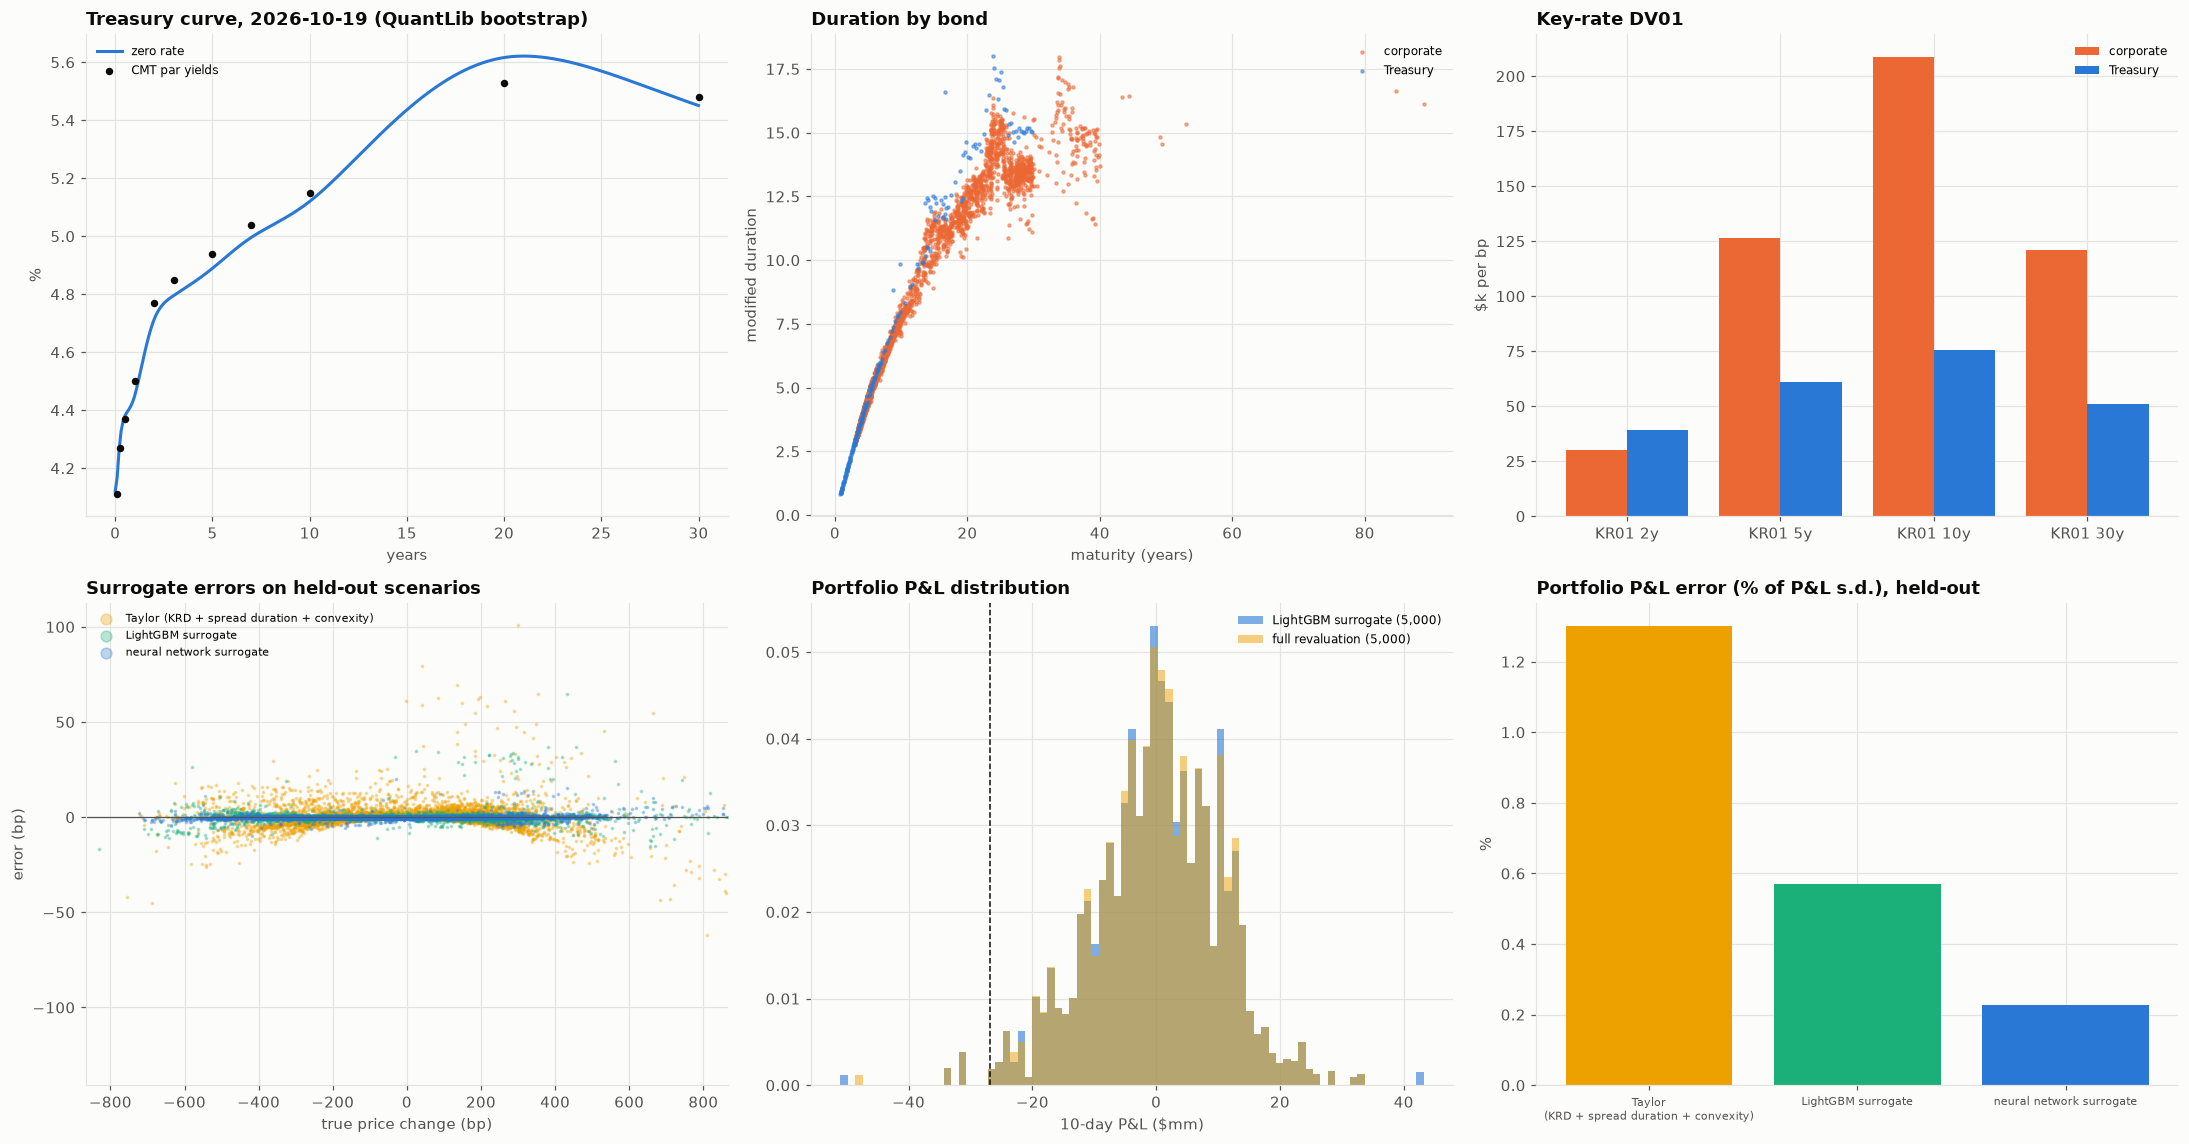

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
ax = axes[0, 0]
grid = np.linspace(0, 30, 301)
ax.plot(
    grid,
    [
        base_curve.zeroRate(float(t_), ql.Continuous).rate() * 100
        for t_ in grid
    ],
    color=PALETTE[0],
    label="zero rate",
)
ax.scatter(
    list(PAR.values()),
    fr.iloc[-1].to_numpy(),
    color=INK,
    s=15,
    zorder=5,
    label="CMT par yields",
)
ax.set_xlabel("years")
ax.set_ylabel("%")
ax.legend(fontsize=8)
ax.set_title(f"Treasury curve, {AS_OF:%Y-%m-%d} (QuantLib bootstrap)")
ax = axes[0, 1]
for f_, c in zip(["LQD", "GOVT"], [PALETTE[1], PALETTE[0]]):
    m_ = risk["fund"] == f_
    ax.scatter(
        risk.loc[m_, "T"],
        risk.loc[m_, "mod. duration"],
        s=4,
        color=c,
        alpha=0.5,
        label="corporate" if f_ == "LQD" else "Treasury",
    )
ax.set_xlabel("maturity (years)")
ax.set_ylabel("modified duration")
ax.legend(fontsize=8)
ax.set_title("Duration by bond")
ax = axes[0, 2]
kr = port.loc[["LQD", "GOVT"], list(KR)] / 1e3
xx = np.arange(len(KR))
ax.bar(xx - 0.2, kr.loc["LQD"], 0.4, color=PALETTE[1], label="corporate")
ax.bar(xx + 0.2, kr.loc["GOVT"], 0.4, color=PALETTE[0], label="Treasury")
ax.set_xticks(xx)
ax.set_xticklabels(list(KR))
ax.set_ylabel("$k per bp")
ax.legend(fontsize=8)
ax.set_title("Key-rate DV01")
ax = axes[1, 0]
lim = np.quantile(np.abs(yte), 0.999) * 1e4
for (k, v), c in zip(pred_te.items(), [PALETTE[3], PALETTE[2], PALETTE[0]]):
    ii = rng.choice(len(v), 20000, replace=False)
    ax.scatter(
        yte[ii] * 1e4,
        (v[ii] - yte[ii]) * 1e4,
        s=2,
        alpha=0.3,
        color=c,
        label=k,
    )
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlim(-lim, lim)
ax.set_xlabel("true price change (bp)")
ax.set_ylabel("error (bp)")
ax.legend(fontsize=7, markerscale=5)
ax.set_title("Surrogate errors on held-out scenarios")
ax = axes[1, 1]
bins = (
    np.linspace(
        np.quantile(pnl["LightGBM surrogate"], 0.001),
        np.quantile(pnl["LightGBM surrogate"], 0.999),
        80,
    )
    / 1e6
)
ax.hist(
    pnl["LightGBM surrogate"] / 1e6,
    bins=bins,
    color=PALETTE[0],
    alpha=0.6,
    density=True,
    label="LightGBM surrogate (5,000)",
)
ax.hist(
    pnl["full revaluation (QuantLib)"] / 1e6,
    bins=bins,
    color=PALETTE[3],
    alpha=0.5,
    density=True,
    label="full revaluation (5,000)",
)
ax.axvline(
    -VAR.loc["LightGBM surrogate", "99% VaR ($mm)"], color=INK, ls="--", lw=1
)
ax.set_xlabel("10-day P&L ($mm)")
ax.legend(fontsize=8)
ax.set_title("Portfolio P&L distribution")
ax = axes[1, 2]
ax.bar(
    ACC.index.str.replace(" (", "\n(", regex=False),
    ACC["P&L error as % of P&L s.d."],
    color=[PALETTE[3], PALETTE[2], PALETTE[0]],
)
ax.set_ylabel("%")
ax.tick_params(axis="x", labelsize=7)
ax.set_title("Portfolio P&L error (% of P&L s.d.), held-out")
plt.tight_layout()
save_fig(fig, "01_quantlib_bond_portfolio_risk")
plt.show()

In [10]:
top = risk.assign(abs_dv01=risk["DV01"].abs()).nlargest(25, "abs_dv01")
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "DV01 vs CS01 by bond ($ per bp)",
        "10-day P&L distribution ($mm)",
    ),
)
for f_, c in zip(["LQD", "GOVT"], [PALETTE[1], PALETTE[0]]):
    m_ = risk["fund"] == f_
    dash.add_trace(
        go.Scatter(
            x=risk.loc[m_, "DV01"],
            y=-risk.loc[m_, "CS01"],
            mode="markers",
            marker=dict(size=4, color=c),
            name="corporate" if f_ == "LQD" else "Treasury",
            text=risk.loc[m_, "Name"],
        ),
        1,
        1,
    )
dash.add_trace(
    go.Histogram(
        x=pnl["LightGBM surrogate"] / 1e6,
        nbinsx=80,
        name="surrogate P&L",
        marker_color=PALETTE[0],
    ),
    1,
    2,
)
dash.update_layout(
    height=560,
    width=1400,
    template="simple_white",
    title="Bond portfolio risk (QuantLib + ML surrogate)",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

**The portfolio.**
- 3,410 bonds priced in QuantLib off the 19 October 2026 Treasury curve (2Y 4.77%, 10Y 5.15%, 30Y 5.48%): 3,181 investment-grade corporates and 229 Treasuries, scaled to $1bn with 60% in corporates.
- Every bond's market price is matched with its own z-spread: median 80 bp for corporates, 1.3 bp for Treasuries, whose small spread is the gap between the smoothed constant-maturity curve and off-the-run bonds.
- Calibration and the eight bump-and-reprice runs take about three seconds for the whole book.

**Sensitivities.**
- Portfolio **DV01 is $713k per bp** (modified duration about 7.1): $486k from corporates and $227k from Treasuries.
- **PV01 is $797k**, about 12% larger than DV01. The two coincide only for bonds priced at par. For a discount (low-coupon) bond, the price sensitivity is smaller than the 1 bp annuity, and most of these bonds trade below par after the rate rise. Treating PV01 as DV01 would mis-size hedges by more than 10%.
- **CS01 is −$712k**. For the corporates it is close to their DV01, as expected for bullet bonds. For Treasuries it equals the curve DV01 by construction, since the z-spread bump is a parallel discount shift, but it is not credit risk.
- **Key-rate DV01s** sum to the parallel DV01 (0.9998). They put 40% of the risk at the 10Y point ($284k), $188k at 5Y, $172k at 30Y and $69k at 2Y. The corporate sleeve is concentrated at 5–10 years, the Treasuries more evenly spread.

**Scenario revaluation.**
- 5,000 resampled 10-day moves from 2000–2026 were all revalued in full, at 63 ms per scenario for the whole book (5 minutes).
- Against that exact benchmark, on 500 held-out scenarios:
  - the **second-order Taylor** expansion (key-rate durations, spread duration, convexity) misses bond prices by 4.0 bp RMSE and portfolio P&L by $142k, 1.3% of the P&L standard deviation;
  - the **LightGBM surrogate** halves this ($62k, 0.6%);
  - the **neural network** cuts it to $25k (0.2%).
- The largest single-bond errors (2–3 points of price) come from short-dated, high-spread bonds in extreme spread scenarios.
- **99% 10-day VaR** is $26.8mm and the 97.5% ES $27.7mm with full revaluation. Taylor gives $26.8mm (−0.1%) and LightGBM $26.9mm (+0.3%).
- Rates alone would give a $29.3mm VaR and credit alone $13.1mm. In history spreads tend to widen when yields fall (flight to quality), so the combined risk is *smaller* than the rate risk alone.

**The honest conclusion on surrogates.**
- For a book of plain fixed-rate bullets, QuantLib full revaluation is cheap, and a good Taylor expansion is already within 1–2% of the exact P&L. The surrogate is not faster here: 40 ms against 63 ms, including feature construction.
- The ML surrogate shows its value as an **approximation that learns the Taylor residual** (cross-convexity, large spread moves) from a few hundred full revaluations. That accuracy carries over to books where full revaluation is genuinely expensive: callables and make-whole options, MBS with prepayment models, structured notes, or intraday what-if analysis on millions of positions.

**Limitations.**
- Make-whole and par calls in corporate bonds are ignored (all bonds treated as bullets), as are sinking funds and floating-rate notes.
- One proportional (DTS-style) spread factor drives all corporates, with no sector or rating dispersion.
- The historical credit factor before 2023 is the Baa–Treasury spread rescaled to the ICE index.
- The Treasury curve comes from constant-maturity par yields rather than a full bond-by-bond fit.
- Scenarios are resampled independently; volatility clustering and autocorrelated 10-day paths are not modelled.

In [11]:
risk.to_csv(OUT_DIR / "bond_level_risk.csv", index=False)
port.to_csv(OUT_DIR / "portfolio_risk_summary.csv")
ACC.to_csv(OUT_DIR / "surrogate_accuracy.csv")
VAR.to_csv(OUT_DIR / "var_es_by_method.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_quantlib_bond_portfolio_risk.png, bond_level_risk.csv, dashboard.html, dashboard.png, portfolio_risk_summary.csv, surrogate_accuracy.csv, var_es_by_method.csv


## References

### Finance and regulation

- Ho, T. S. Y. (1992). Key rate durations: Measures of interest rate risks. *The Journal of Fixed Income, 2*(2), 29–44. https://doi.org/10.3905/jfi.1992.408049
- Tuckman, B., & Serrat, A. (2022). *Fixed income securities: Tools for today's markets* (4th ed.). Wiley. https://doi.org/10.1002/9781119835622
- Basel Committee on Banking Supervision. (2019). *Minimum capital requirements for market risk*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d457.htm
- Ballotta, L., & Fusai, G. (2017). A gentle introduction to value at risk. *SSRN Electronic Journal*. https://doi.org/10.2139/ssrn.2942138

### Machine learning and deep learning

- Ballabio, L. (2020). *Implementing QuantLib*. Leanpub. https://leanpub.com/implementingquantlib
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Ferguson, R., & Green, A. (2018). Deeply learning derivatives. *arXiv*. https://arxiv.org/abs/1809.02233
- Hornik, K., Stinchcombe, M., & White, H. (1989). Multilayer feedforward networks are universal approximators. *Neural Networks, 2*(5), 359–366. https://doi.org/10.1016/0893-6080(89)90020-8